# BDC Pitch EDA: is private credit's NAV real?

**Setup.** A BDC owns private loans that never trade. The manager estimates (marks) what each loan is worth every
quarter, and NAV is built from those marks. Listed BDCs trade below NAV. Either the market is too pessimistic,
or the marks are too optimistic and NAV will be cut.

**Questions.**
1. **Who is right?** Does a deep discount predict future NAV cuts (market right) or future price gains (marks right)?
2. **Are marks stale?** Do BDC NAVs follow the public loan market (BKLN) with a lag? Does the BDC share price move first?
3. **Are some managers optimistic?** Many loans are held by several BDCs. When one BDC marks a shared loan above what
   the other BDCs mark it, does that mark later get cut? Does an optimistic BDC see NAV cuts or price underperformance?

**Data.** SEC EDGAR XBRL (NAV/share; every investment's fair value, cost, principal from each 10-Q/10-K schedule of
investments), Yahoo Finance prices. BDC financials were only XBRL-tagged from 2022, so the quarterly sample is
**2022Q2 to 2026Q2**. Each quarter's signal uses only data filed by **period end + 95 days** (the latest 10-K
deadline); positions are held until the next quarter's signal date.

## 1. Data

In [1]:
import warnings; warnings.filterwarnings("ignore")
import re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("data")
LAG_DAYS = 95          # signal date = period end + 95 days (all 10-Q/10-K filed by then)
MIN_PEERS = 2          # a loan's peer mark needs at least this many other BDCs
MIN_SHARED = 10        # a BDC-quarter optimism score needs at least this many shared loans

uni = pd.read_csv(DATA / "universe.csv")
listed = set(uni.loc[uni.listed, "ticker"])
nav = pd.read_csv(DATA / "bdc_nav.csv", parse_dates=["period_end", "filed"])
nav = nav[nav.period_end.dt.is_quarter_end & nav.nav_ps.gt(0)].copy()
# a value first reported long after the quarter (comparative columns) was not known in time: drop it
nav = nav[(nav.filed - nav.period_end).dt.days <= LAG_DAYS]
nav = nav.sort_values(["ticker", "period_end"]).drop_duplicates(["ticker", "period_end"])
nav = nav[nav.period_end >= "2022-03-31"]

px = pd.read_csv(DATA / "prices.csv", parse_dates=["date"])
close = px.pivot(index="date", columns="ticker", values="close")
adj = px.pivot(index="date", columns="ticker", values="adj_close")
cal = close.index

def bucket(x, k):
    # cross-sectional k-tile (1 = lowest); NaN when a quarter has too few names
    if x.notna().sum() < 2 * k:
        return pd.Series(np.nan, index=x.index)
    return pd.qcut(x.rank(method="first"), k, labels=False) + 1

def on_or_after(d):
    i = cal.searchsorted(d)
    return cal[min(i, len(cal) - 1)]

print(f"NAV rows {len(nav)}, BDCs {nav.ticker.nunique()} ({len(set(nav.ticker) & listed)} listed), "
      f"quarters {nav.period_end.min().date()} .. {nav.period_end.max().date()}")

NAV rows 686, BDCs 47 (41 listed), quarters 2022-06-30 .. 2026-06-30


## 2. The discount
**What this does.** Daily price / last-filed NAV − 1 for each listed BDC (NAV switches on the day it is filed).

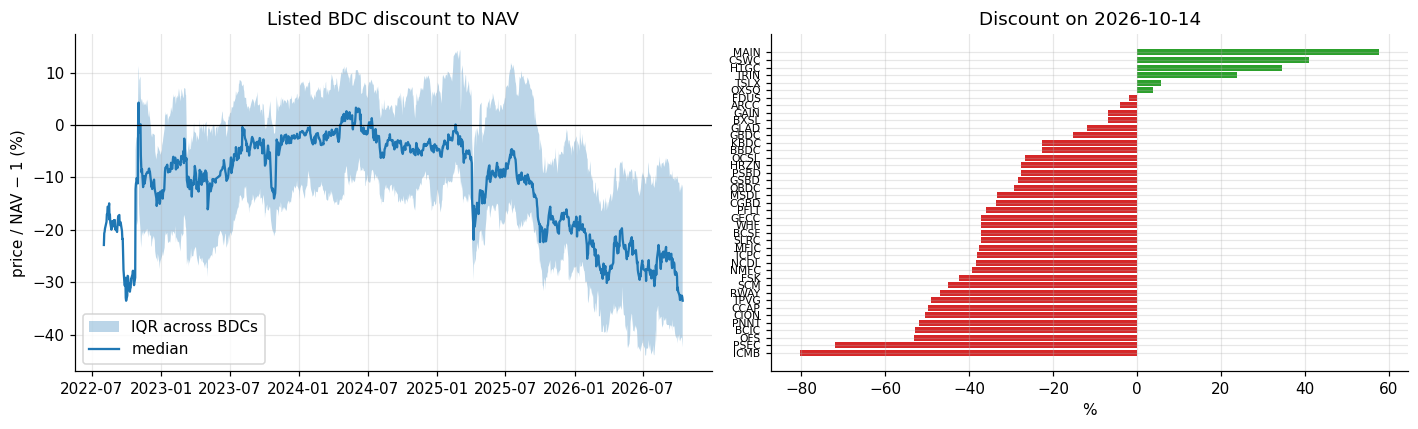

median discount now -33.5%; 29 of 41 BDCs below -20%


In [2]:
rows = []
for t in sorted(set(nav.ticker) & listed & set(close.columns)):
    n = nav[nav.ticker == t][["filed", "nav_ps"]].sort_values("filed")
    p = close[t].dropna().rename("close").reset_index()
    p = p[p.date >= "2022-06-01"]
    m = pd.merge_asof(p, n, left_on="date", right_on="filed")
    m["ticker"] = t
    rows.append(m)
daily = pd.concat(rows).dropna(subset=["nav_ps"])
daily["disc"] = daily.close / daily.nav_ps - 1
D = daily.pivot(index="date", columns="ticker", values="disc")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
med = D.median(axis=1)
ax[0].fill_between(D.index, D.quantile(0.25, axis=1) * 100, D.quantile(0.75, axis=1) * 100, alpha=0.3, label="IQR across BDCs")
ax[0].plot(med.index, med * 100, lw=1.5, label="median")
ax[0].axhline(0, c="k", lw=0.8); ax[0].set_ylabel("price / NAV − 1 (%)"); ax[0].set_title("Listed BDC discount to NAV"); ax[0].legend()
last = D.ffill().iloc[-1].dropna().sort_values()
ax[1].barh(last.index, last * 100, color=np.where(last < 0, "tab:red", "tab:green"))
ax[1].set_title(f"Discount on {D.index[-1].date()}"); ax[1].set_xlabel("%"); ax[1].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()
print(f"median discount now {med.iloc[-1]:.1%}; {(last < -0.2).sum()} of {len(last)} BDCs below -20%")

## 3. Quarterly panel
**What this does.** One row per BDC-quarter. Signal date s_q = period end + 95 days. At s_q we know NAV_q.
* `disc`: price at s_q / NAV_q − 1.
* `fnav1`, `fnav2`, `fnav4`: NAV change from q to q+1, q+2, q+4 (the outcome if marks get cut).
* `fret1`: total return (dividends reinvested) from s_q to s_{q+1} (what a trade earns).
* `cs_*`: minus that quarter's cross-sectional median, so market-wide moves do not drive the results.

In [3]:
qs = sorted(nav.period_end.unique())
sig_date = {q: on_or_after(pd.Timestamp(q) + pd.Timedelta(days=LAG_DAYS)) for q in qs}
nv = nav.pivot(index="period_end", columns="ticker", values="nav_ps")
panel = []
for i, q in enumerate(qs):
    s = sig_date[q]
    for t in nv.columns:
        if t not in listed or t not in close.columns or pd.isna(nv.at[q, t]):
            continue
        p = close[t].asof(s)
        r = {"ticker": t, "q": q, "s": s, "nav": nv.at[q, t], "disc": p / nv.at[q, t] - 1}
        for k in (1, 2, 4):
            r[f"fnav{k}"] = nv.at[qs[i + k], t] / nv.at[q, t] - 1 if i + k < len(qs) else np.nan
        r["pnav1"] = nv.at[q, t] / nv.at[qs[i - 1], t] - 1 if i >= 1 else np.nan
        if i + 1 < len(qs) and sig_date[qs[i + 1]] <= cal[-1]:
            a = adj[t]; r["fret1"] = a.asof(sig_date[qs[i + 1]]) / a.asof(s) - 1
        else:
            r["fret1"] = np.nan
        panel.append(r)
P = pd.DataFrame(panel)
for c in ["disc", "fnav1", "fnav2", "fnav4", "fret1", "pnav1"]:
    P["cs_" + c] = P[c] - P.groupby("q")[c].transform("median")
P["qn"] = P.groupby("q").disc.transform("count")
P["disc_q"] = P.groupby("q").disc.transform(lambda x: bucket(x, 5))
print(P.groupby("q").agg(n=("ticker", "count"), med_disc=("disc", "median"), med_fnav1=("fnav1", "median")).round(3).to_string())

             n  med_disc  med_fnav1
q                                  
2022-06-30   1    -0.325     -0.009
2022-09-30  36    -0.136     -0.014
2022-12-31  38    -0.109      0.001
2023-03-31  41    -0.062      0.001
2023-06-30  41    -0.078      0.005
2023-09-30  40    -0.021      0.003
2023-12-31  41    -0.018      0.002
2024-03-31  41     0.005     -0.005
2024-06-30  41    -0.052     -0.004
2024-09-30  41    -0.045     -0.003
2024-12-31  40    -0.182     -0.011
2025-03-31  41    -0.083     -0.007
2025-06-30  41    -0.200     -0.007
2025-09-30  41    -0.175     -0.009
2025-12-31  41    -0.268     -0.025
2026-03-31  41    -0.277     -0.010
2026-06-30  41    -0.324        NaN


## 4. Q1: who is right, the market or the marks?
**Test.** If the market is right, BDCs with deeper discounts (lower `disc`) should see bigger NAV cuts afterwards,
so `disc` and future NAV change should be **positively** related. If the marks are right, the discount should
instead close through the price: deep-discount BDCs earn higher returns (negative relation with `fret1`).

In [4]:
def spear(x, y):
    m = x.notna() & y.notna()
    r, p = stats.spearmanr(x[m], y[m]); return r, p, m.sum()

print("Spearman, cross-sectionally demeaned discount vs outcome")
for y in ["cs_fnav1", "cs_fnav2", "cs_fnav4", "cs_fret1"]:
    r, p, n = spear(P.cs_disc, P[y]); print(f"  {y:9s} rho={r:+.3f}  p={p:.4f}  n={n}")

# Fama-MacBeth: slope of next-quarter NAV change on discount, one regression per quarter (no overlap)
fm = []
for q, g in P.dropna(subset=["disc", "fnav1"]).groupby("q"):
    if len(g) >= 15:
        fm.append(sm.OLS(g.fnav1, sm.add_constant(g.disc)).fit().params["disc"])
fm = np.array(fm)
print(f"\nFama-MacBeth slope fnav1 ~ disc: mean {fm.mean():+.4f}, t = {fm.mean() / (fm.std(ddof=1) / np.sqrt(len(fm))):.2f}, "
      f"{(fm > 0).mean():.0%} of {len(fm)} quarters positive")

Spearman, cross-sectionally demeaned discount vs outcome
  cs_fnav1  rho=+0.334  p=0.0000  n=586
  cs_fnav2  rho=+0.402  p=0.0000  n=546
  cs_fnav4  rho=+0.399  p=0.0000  n=464
  cs_fret1  rho=+0.052  p=0.2085  n=589

Fama-MacBeth slope fnav1 ~ disc: mean +0.0579, t = 2.76, 100% of 15 quarters positive


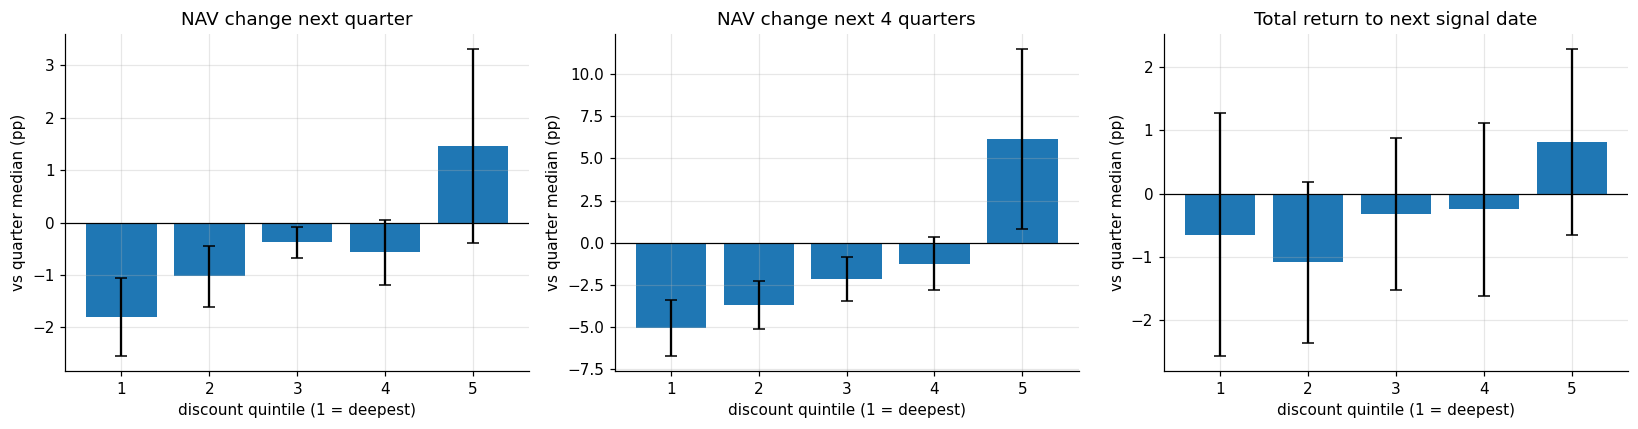

cs_fnav1  Kruskal-Wallis H= 60.42 p=0.0000 | Q1 mean -1.80% vs Q5 +1.46%, Welch t=-3.22 p=0.0016
cs_fnav4  Kruskal-Wallis H= 64.49 p=0.0000 | Q1 mean -5.05% vs Q5 +6.14%, Welch t=-3.93 p=0.0001
cs_fret1  Kruskal-Wallis H=  2.86 p=0.5816 | Q1 mean -0.64% vs Q5 +0.82%, Welch t=-1.19 p=0.2361


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, y, ttl in [(ax[0], "cs_fnav1", "NAV change next quarter"), (ax[1], "cs_fnav4", "NAV change next 4 quarters"),
                  (ax[2], "cs_fret1", "Total return to next signal date")]:
    g = P.dropna(subset=[y]).groupby("disc_q")[y]
    a.bar(g.mean().index, g.mean() * 100, yerr=g.sem() * 100 * 1.96, capsize=4, color="tab:blue")
    a.axhline(0, c="k", lw=0.8); a.set_title(ttl); a.set_xlabel("discount quintile (1 = deepest)"); a.set_ylabel("vs quarter median (pp)")
plt.tight_layout(); plt.show()

for y in ["cs_fnav1", "cs_fnav4", "cs_fret1"]:
    d = P.dropna(subset=[y])
    groups = [g[y].values for _, g in d.groupby("disc_q")]
    H, pH = stats.kruskal(*groups)
    q1, q5 = d[d.disc_q == 1][y], d[d.disc_q == 5][y]
    t, pt = stats.ttest_ind(q1, q5, equal_var=False)
    print(f"{y:9s} Kruskal-Wallis H={H:6.2f} p={pH:.4f} | Q1 mean {q1.mean():+.2%} vs Q5 {q5.mean():+.2%}, Welch t={t:+.2f} p={pt:.4f}")

**Robustness.** (a) BDCs trading above NAV (MAIN, HTGC, CSWC…) can issue new shares above NAV, which raises NAV
mechanically and could drive the Q5 result, so rerun on discount names only. (b) Split the sample: first half of
signal quarters (2022Q3–2024Q2) vs second half (2024Q3 onward).

In [6]:
half = pd.Timestamp("2024-06-30")
for nm, d in [("all", P), ("discount names only (disc < 0)", P[P.disc < 0]),
              ("first half", P[P.q <= half]), ("second half", P[P.q > half])]:
    d = d.copy(); d["cs_d"] = d.disc - d.groupby("q").disc.transform("median")
    out = []
    for y in ["fnav1", "fnav4", "fret1"]:
        yy = d[y] - d.groupby("q")[y].transform("median")
        r, p, n = spear(d.cs_d, yy); out.append(f"{y} rho={r:+.2f} (p={p:.3f}, n={n})")
    print(f"{nm:32s} " + " | ".join(out))

all                              fnav1 rho=+0.33 (p=0.000, n=586) | fnav4 rho=+0.40 (p=0.000, n=464) | fret1 rho=+0.05 (p=0.209, n=589)
discount names only (disc < 0)   fnav1 rho=+0.21 (p=0.000, n=417) | fnav4 rho=+0.16 (p=0.005, n=316) | fret1 rho=+0.01 (p=0.821, n=420)
first half                       fnav1 rho=+0.20 (p=0.000, n=301) | fnav4 rho=+0.29 (p=0.000, n=301) | fret1 rho=-0.05 (p=0.373, n=303)
second half                      fnav1 rho=+0.45 (p=0.000, n=285) | fnav4 rho=+0.58 (p=0.000, n=163) | fret1 rho=+0.13 (p=0.025, n=286)


**Who closes the gap?** For each BDC-quarter, the discount over the next four quarters can close either because the
price rises or because NAV falls. Split the deepest-discount quintile's realised change in log(price/NAV) into the two parts.

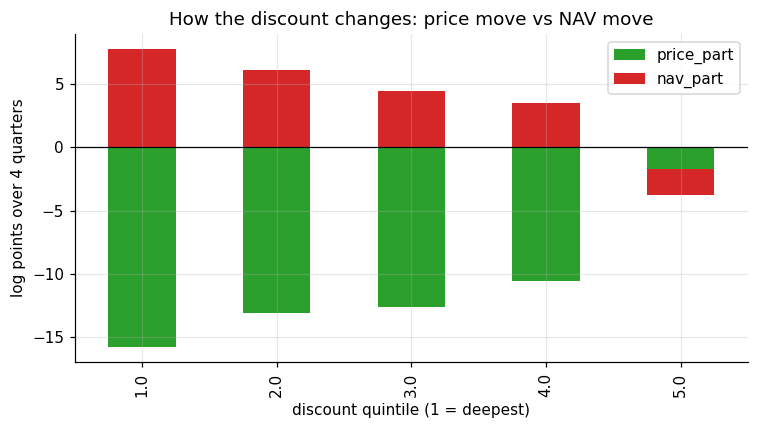

        price_part  nav_part  total gap change
disc_q                                        
1.0         -15.76      7.73             -8.03
2.0         -13.10      6.04             -7.05
3.0         -12.63      4.42             -8.20
4.0         -10.56      3.49             -7.07
5.0          -1.74     -2.07             -3.81
price_part > 0: price rose. nav_part > 0: NAV fell. Both narrow the discount.


In [7]:
rows = []
for _, r in P.iterrows():
    i = qs.index(r.q)
    if i + 4 >= len(qs) or sig_date[qs[i + 4]] > cal[-1]:
        continue
    t = r.ticker; s1 = sig_date[qs[i + 4]]
    p0, p1 = close[t].asof(r.s), close[t].asof(s1)
    n1 = nv.at[qs[i + 4], t]
    if pd.isna(n1) or pd.isna(p1):
        continue
    rows.append({"disc_q": r.disc_q, "price_part": np.log(p1 / p0), "nav_part": -np.log(n1 / r.nav)})
dec = pd.DataFrame(rows).groupby("disc_q").mean() * 100
dec["total gap change"] = dec.sum(axis=1)
ax = dec[["price_part", "nav_part"]].plot.bar(stacked=True, figsize=(7, 4), color=["tab:green", "tab:red"])
ax.set_ylabel("log points over 4 quarters"); ax.set_title("How the discount changes: price move vs NAV move")
ax.set_xlabel("discount quintile (1 = deepest)"); plt.axhline(0, c="k", lw=0.8); plt.tight_layout(); plt.show()
print(dec.round(2).to_string())
print("price_part > 0: price rose. nav_part > 0: NAV fell. Both narrow the discount.")

## 5. Q2: are marks stale?
**Test 1 (aggregate).** Regress the median BDC NAV change in quarter q on public loan returns (BKLN, total return)
in quarter q and the two quarters before. Fresh marks load on the same quarter only. Stale marks also load on lags.

**Test 2 (each BDC).** Does a BDC's own share price return in quarter q predict its NAV change in quarter q+1,
after controlling for its NAV change in q? If yes, the market sees changes before the marks do.

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0209      0.003     -6.920      0.000      -0.027      -0.015
bkln           0.4266      0.098      4.375      0.000       0.236       0.618
bkln_l1        0.2033      0.084      2.431      0.015       0.039       0.367
bkln_l2        0.1559      0.030      5.114      0.000       0.096       0.216
autocorrelation: median BDC NAV change +0.50, BKLN quarterly return +0.23


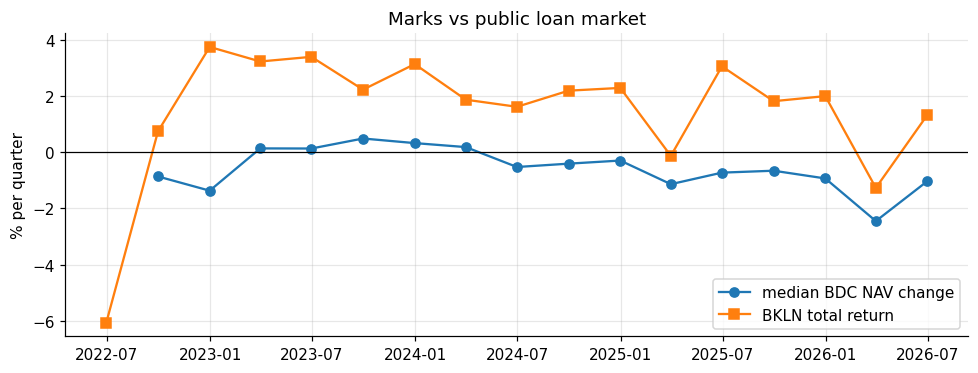

In [8]:
qe = pd.DatetimeIndex(qs)
bk = adj["BKLN"]
qret = lambda s: pd.Series([s.asof(q) / s.asof(q - pd.offsets.QuarterEnd(1)) - 1 for q in qe], index=qe)
agg = pd.DataFrame({"nav_chg": nv[sorted(set(nv.columns) & listed)].pct_change().median(axis=1).reindex(qe),
                    "bkln": qret(bk), "hyg": qret(adj["HYG"])})
agg["bkln_l1"], agg["bkln_l2"] = agg.bkln.shift(1), agg.bkln.shift(2)
a = agg.dropna()
fit = sm.OLS(a.nav_chg, sm.add_constant(a[["bkln", "bkln_l1", "bkln_l2"]])).fit(cov_type="HC1")
print(fit.summary().tables[1])
print(f"autocorrelation: median BDC NAV change {agg.nav_chg.autocorr():+.2f}, BKLN quarterly return {agg.bkln.autocorr():+.2f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(agg.index, agg.nav_chg * 100, marker="o", label="median BDC NAV change")
ax.plot(agg.index, agg.bkln * 100, marker="s", label="BKLN total return")
ax.axhline(0, c="k", lw=0.8); ax.set_ylabel("% per quarter"); ax.legend(); ax.set_title("Marks vs public loan market")
plt.tight_layout(); plt.show()

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0033      0.002     -1.407      0.159      -0.008       0.001
cs_pret        0.0373      0.024      1.584      0.113      -0.009       0.083
cs_dnav        0.1536      0.086      1.787      0.074      -0.015       0.322


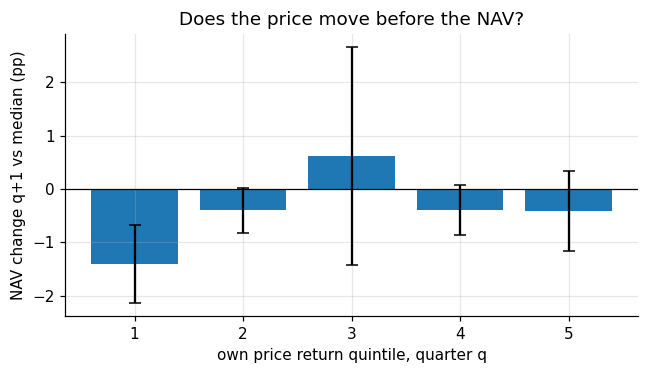

In [9]:
# own price return over quarter q (calendar quarter, ex-dividend price change via adj close) vs NAV change q -> q+1
rows = []
for t in sorted(set(nv.columns) & listed & set(adj.columns)):
    for i in range(1, len(qs) - 1):
        q0, q1, q2 = qs[i - 1], qs[i], qs[i + 1]
        n0, n1, n2 = nv.at[q0, t], nv.at[q1, t], nv.at[q2, t]
        a0, a1 = adj[t].asof(q0), adj[t].asof(q1)
        if np.isnan([n0, n1, n2, a0, a1]).any():
            continue
        rows.append({"ticker": t, "q": q1, "pret": a1 / a0 - 1, "dnav": n1 / n0 - 1, "fdnav": n2 / n1 - 1})
L = pd.DataFrame(rows)
for c in ["pret", "dnav", "fdnav"]:
    L["cs_" + c] = L[c] - L.groupby("q")[c].transform("median")
fit2 = sm.OLS(L.cs_fdnav, sm.add_constant(L[["cs_pret", "cs_dnav"]])).fit(cov_type="cluster", cov_kwds={"groups": L.q.astype("int64")})
print(fit2.summary().tables[1])
L["pret_q"] = L.groupby("q").cs_pret.transform(lambda x: bucket(x, 5))
g = L.groupby("pret_q").cs_fdnav
plt.figure(figsize=(6, 3.5)); plt.bar(g.mean().index, g.mean() * 100, yerr=g.sem() * 196, capsize=4)
plt.axhline(0, c="k", lw=0.8); plt.xlabel("own price return quintile, quarter q"); plt.ylabel("NAV change q+1 vs median (pp)")
plt.title("Does the price move before the NAV?"); plt.tight_layout(); plt.show()

## 6. Q3: are some managers optimistic? Shared loans across BDCs
**What this does.** Every investment from every 10-Q/10-K schedule (listed and large non-traded BDCs). For debt with a
principal amount, mark = fair value / principal (a price in points, like a loan quote). Revolvers and delayed-draw
tranches are dropped (unfunded amounts distort the mark).

**Matching the same loan.** Each BDC writes identifiers differently, so borrowers are matched with `borrowers.py`
(a vocabulary of company names learned from all filings, found inside each identifier). A "loan" = borrower + spread
over SOFR rounded to 0.25%. Two BDCs holding the same company at the same spread almost always hold the same
facility; different tranches of one company (1st vs 2nd lien) have different spreads and are kept apart.

For each loan and quarter, a BDC's **gap** = its own principal-weighted mark − the median mark of the *other* BDCs
holding the same loan (needs ≥ 2 others). Gap > 0 means the BDC values the loan higher than its peers do.

In [10]:
from borrowers import assign
pos = pd.read_csv(DATA / "bdc_positions.csv.gz", parse_dates=["period_end", "filed"], low_memory=False)
pos = pos[pos.identifier.notna() & pos.principal.gt(0) & pos.fv.notna()]
pos = pos[~pos.identifier.str.contains(r"revolv|delayed|ddtl|\bdelay|unfunded", case=False, regex=True)]
pos["mark"] = pos.fv / pos.principal
pos = pos[pos.mark.between(0.02, 1.15) & pos.principal.ge(1e6)]
pos["name"], vocab = assign(pos)
pos["spread_n"] = np.where(pos.spread > 0.5, pos.spread / 100, pos.spread)   # some filers tag 5.75, others 0.0575
pos = pos[pos.name.notna() & pos.spread_n.between(0.005, 0.2)]
pos["borrower"] = pos.name + " @" + (np.round(pos.spread_n * 400) / 4).map(lambda x: f"{x:.2f}")

# one mark per BDC x loan x quarter (principal-weighted)
bq = (pos.assign(w=pos.mark * pos.principal).groupby(["ticker", "period_end", "borrower"])
         .agg(w=("w", "sum"), principal=("principal", "sum"), fv=("fv", "sum")).reset_index())
bq["mark"] = bq.w / bq.principal
grp = bq.groupby(["period_end", "borrower"])
bq["n_bdc"] = grp.ticker.transform("count")

def loo_median(g):
    m = g.mark.values
    return pd.Series([np.median(np.delete(m, i)) if len(m) > 1 else np.nan for i in range(len(m))], index=g.index)
sh = bq[bq.n_bdc >= MIN_PEERS + 1].copy()
sh["peer"] = sh.groupby(["period_end", "borrower"], group_keys=False).apply(loo_median)
sh["gap"] = sh.mark - sh.peer

tot = bq.groupby(["ticker", "period_end"]).principal.sum()
cov = (sh.groupby(["ticker", "period_end"]).principal.sum() / tot).groupby("ticker").median().sort_values()
print(f"positions {len(pos):,}; BDC-borrower-quarters {len(bq):,}; shared ({MIN_PEERS + 1}+ holders): {len(sh):,}")
print(f"distinct shared borrowers per quarter (median): {sh.groupby('period_end').borrower.nunique().median():.0f}")
print("median share of each BDC's debt principal that is in shared borrowers:")
print((cov * 100).round(0).to_string())

positions 100,161; BDC-borrower-quarters 75,476; shared (3+ holders): 23,517
distinct shared borrowers per quarter (median): 400
median share of each BDC's debt principal that is in shared borrowers:
ticker
GAIN      1.0
TPVG      1.0
HTGC      2.0
CSWC      3.0
GECC      4.0
OFS       4.0
GLAD      5.0
SCM       6.0
FDUS      7.0
CION      8.0
PSEC     10.0
MAIN     10.0
BCSF     11.0
SLRC     11.0
BBDC     12.0
RWAY     13.0
TRIN     16.0
WHF      16.0
NCDL     19.0
FSK      21.0
BCIC     23.0
PFLT     25.0
ICMB     26.0
MFIC     27.0
ARCC     29.0
TCPC     30.0
PNNT     30.0
GBDC     32.0
CGBD     35.0
BXSL     37.0
KBDC     39.0
PSBD     40.0
CCAP     41.0
GSBD     41.0
BCRED    42.0
ASIF     44.0
OCSL     45.0
HLEND    48.0
ADS      49.0
GCRED    50.0
NMFC     52.0
OBDC     52.0
MSDL     53.0
OSCF     54.0
OCIC     58.0
NHPIF    74.0
SAR       NaN


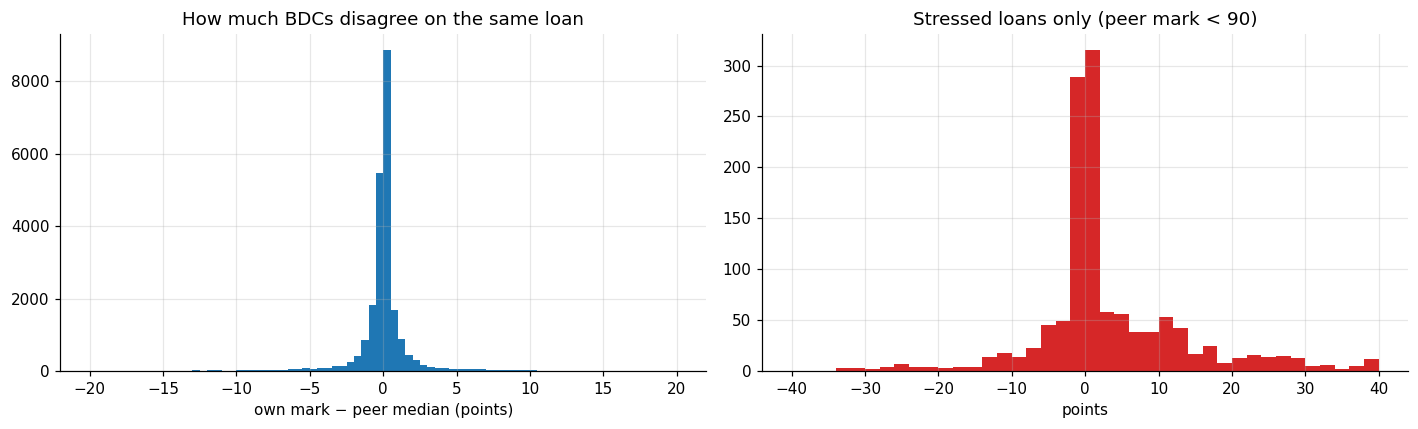

all shared             n= 23517  |gap| median 0.28pt, 90th pct 2.73pt, share |gap| > 5pt 6.2%
stressed (peer < 90)   n=  1284  |gap| median 2.63pt, 90th pct 25.00pt, share |gap| > 5pt 40.7%


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(sh.gap * 100, bins=np.arange(-20, 20.5, 0.5), color="tab:blue")
ax[0].set_xlabel("own mark − peer median (points)"); ax[0].set_title("How much BDCs disagree on the same loan")
stress = sh[sh.peer < 0.9]
ax[1].hist(stress.gap * 100, bins=np.arange(-40, 40.5, 2), color="tab:red")
ax[1].set_xlabel("points"); ax[1].set_title("Stressed loans only (peer mark < 90)")
plt.tight_layout(); plt.show()
for nm, d in [("all shared", sh), ("stressed (peer < 90)", stress)]:
    print(f"{nm:22s} n={len(d):6d}  |gap| median {d.gap.abs().median() * 100:.2f}pt, 90th pct {d.gap.abs().quantile(0.9) * 100:.2f}pt, "
          f"share |gap| > 5pt {(d.gap.abs() > 0.05).mean():.1%}")

**Test: who moves when BDCs disagree?** For a BDC-borrower with gap g at quarter q, compare next quarter's change in
the BDC's own mark with the change in the peer median. If the outlier BDC is wrong, its own mark moves toward the
peers (Δown has slope < 0 on g) while the peers barely move. If the outlier is right (it knew first), peers move
toward it (Δpeer has slope > 0). Rounding in reported marks also pulls Δown toward the peers, so the
comparison between the two slopes matters more than either alone.

d_own  = -0.0021 -0.161 * gap   (t on gap -4.8, n=15969)
d_peer = -0.0015 +0.095 * gap   (t on gap +5.2, n=15969)


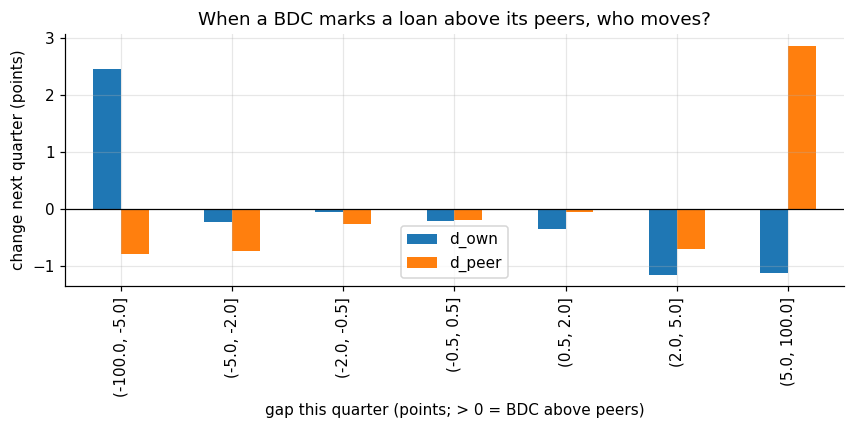

                d_own  d_peer
gap_b                        
(-100.0, -5.0]   2.46   -0.79
(-5.0, -2.0]    -0.23   -0.74
(-2.0, -0.5]    -0.06   -0.27
(-0.5, 0.5]     -0.21   -0.20
(0.5, 2.0]      -0.35   -0.06
(2.0, 5.0]      -1.16   -0.71
(5.0, 100.0]    -1.13    2.87

stressed loans marked >5pt above peers: n=256, next-quarter own change -1.46pt, peer change +4.16pt, own − peer t = -7.35


In [12]:
sh = sh.sort_values("period_end")
qlist = sorted(sh.period_end.unique()); nxt = dict(zip(qlist[:-1], qlist[1:]))
cur = sh[["ticker", "period_end", "borrower", "mark", "peer", "gap"]].copy()
cur["next_q"] = cur.period_end.map(nxt)
fut = sh[["ticker", "period_end", "borrower", "mark", "peer"]].rename(columns={"period_end": "next_q", "mark": "mark1", "peer": "peer1"})
M = cur.merge(fut, on=["ticker", "next_q", "borrower"])
M["d_own"], M["d_peer"] = M.mark1 - M.mark, M.peer1 - M.peer
out = {}
for y in ["d_own", "d_peer"]:
    f = sm.OLS(M[y], sm.add_constant(M.gap)).fit(cov_type="cluster", cov_kwds={"groups": M.borrower.factorize()[0]})
    out[y] = f; print(f"{y:6s} = {f.params['const']:+.4f} {f.params['gap']:+.3f} * gap   (t on gap {f.tvalues['gap']:+.1f}, n={len(M)})")

M["gap_b"] = pd.cut(M.gap * 100, [-100, -5, -2, -0.5, 0.5, 2, 5, 100])
g = M.groupby("gap_b", observed=True)[["d_own", "d_peer"]].mean() * 100
g.plot.bar(figsize=(8, 4)); plt.axhline(0, c="k", lw=0.8)
plt.ylabel("change next quarter (points)"); plt.xlabel("gap this quarter (points; > 0 = BDC above peers)")
plt.title("When a BDC marks a loan above its peers, who moves?"); plt.tight_layout(); plt.show()
print(g.round(2).to_string())

# optimistic outliers on stressed loans: do they get marked down more than the peers?
hi = M[(M.gap > 0.05) & (M.peer < 0.9)]
print(f"\nstressed loans marked >5pt above peers: n={len(hi)}, next-quarter own change {hi.d_own.mean() * 100:+.2f}pt, "
      f"peer change {hi.d_peer.mean() * 100:+.2f}pt, own − peer t = {stats.ttest_1samp(hi.d_own - hi.d_peer, 0).statistic:+.2f}")

## 7. Q3 at the fund level: optimism score
**What this does.** Each BDC-quarter's **optimism** = principal-weighted mean gap across its shared loans (at least
10 shared borrowers). Then: is optimism priced into the discount already? Does it predict NAV cuts or returns?

BDC-quarters with an optimism score: 293 (26 listed BDCs)

Spearman, optimism (demeaned) vs:
  cs_disc   rho=-0.072 p=0.2243 n=289
  cs_fnav1  rho=+0.014 p=0.8205 n=273
  cs_fnav2  rho=+0.044 p=0.4886 n=254
  cs_fnav4  rho=+0.062 p=0.3626 n=217
  cs_fret1  rho=-0.033 p=0.5881 n=269


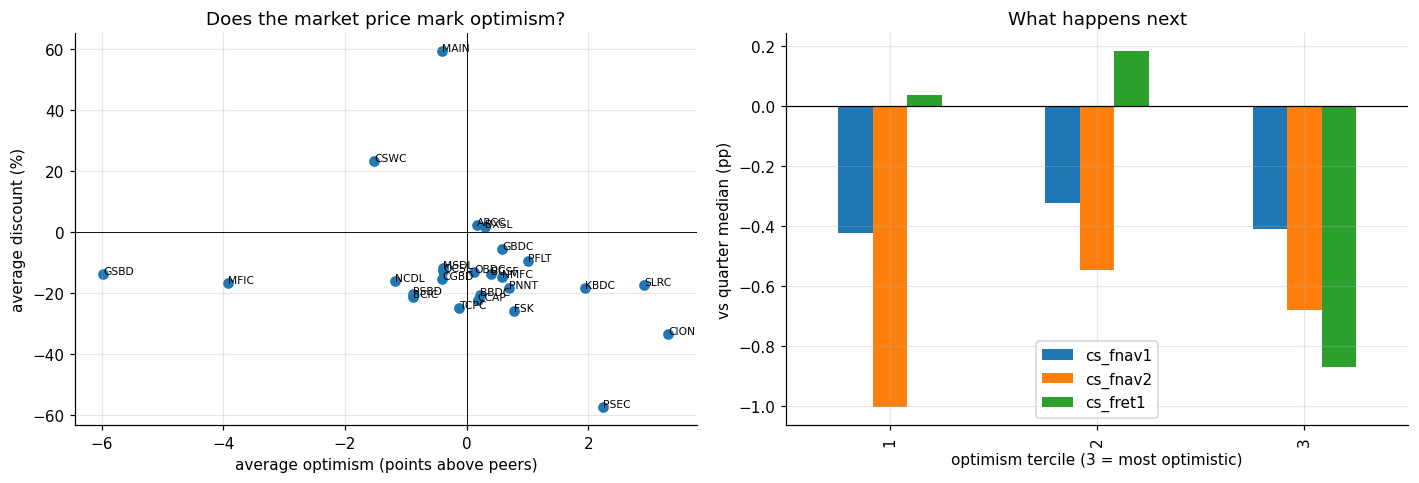

       cs_fnav1  cs_fnav2  cs_fret1
opt_t                              
1         -0.42     -1.00      0.04
2         -0.32     -0.55      0.18
3         -0.41     -0.68     -0.87


In [13]:
sh["w"] = sh.gap * sh.principal
opt = sh.groupby(["ticker", "period_end"]).agg(w=("w", "sum"), pr=("principal", "sum"), n=("borrower", "count")).reset_index()
opt = opt[opt.n >= MIN_SHARED]
opt["optimism"] = opt.w / opt.pr
X = P.merge(opt[["ticker", "period_end", "optimism", "n"]], left_on=["ticker", "q"], right_on=["ticker", "period_end"])
X["cs_opt"] = X.optimism - X.groupby("q").optimism.transform("median")
print(f"BDC-quarters with an optimism score: {len(X)} ({X.ticker.nunique()} listed BDCs)")
print("\nSpearman, optimism (demeaned) vs:")
for y in ["cs_disc", "cs_fnav1", "cs_fnav2", "cs_fnav4", "cs_fret1"]:
    r, p, n = spear(X.cs_opt, X[y]); print(f"  {y:9s} rho={r:+.3f} p={p:.4f} n={n}")

avg = X.groupby("ticker").agg(opt=("optimism", "mean"), disc=("disc", "mean")).dropna()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(avg.opt * 100, avg.disc * 100)
for t, r in avg.iterrows(): ax[0].annotate(t, (r.opt * 100, r.disc * 100), fontsize=7)
ax[0].axhline(0, c="k", lw=0.6); ax[0].axvline(0, c="k", lw=0.6)
ax[0].set_xlabel("average optimism (points above peers)"); ax[0].set_ylabel("average discount (%)"); ax[0].set_title("Does the market price mark optimism?")
X["opt_t"] = X.groupby("q").cs_opt.transform(lambda x: bucket(x, 3))
g = X.groupby("opt_t")[["cs_fnav1", "cs_fnav2", "cs_fret1"]].mean() * 100
g.plot.bar(ax=ax[1]); ax[1].axhline(0, c="k", lw=0.8); ax[1].set_xlabel("optimism tercile (3 = most optimistic)")
ax[1].set_ylabel("vs quarter median (pp)"); ax[1].set_title("What happens next")
plt.tight_layout(); plt.show()
print(g.round(2).to_string())

## 8. Does it trade? A first long/short
**What this does.** Each quarter at the signal date, rank listed BDCs on a composite: **cheap** (deep discount) and
**honest** (low optimism) = z(−disc) + z(−optimism). Long the top third, short the bottom third, equal weight,
hold to the next signal date, total returns, no costs. The sample is about 15 quarters, so this is a sanity check,
not a backtest. Compare with discount-only and optimism-only sorts.

          quarters  mean per q  hit rate  ann. Sharpe      t
z_cheap         15       0.008     0.533        0.468  0.905
z_honest        15       0.011     0.667        0.656  1.269
combo           15       0.007     0.600        0.327  0.634


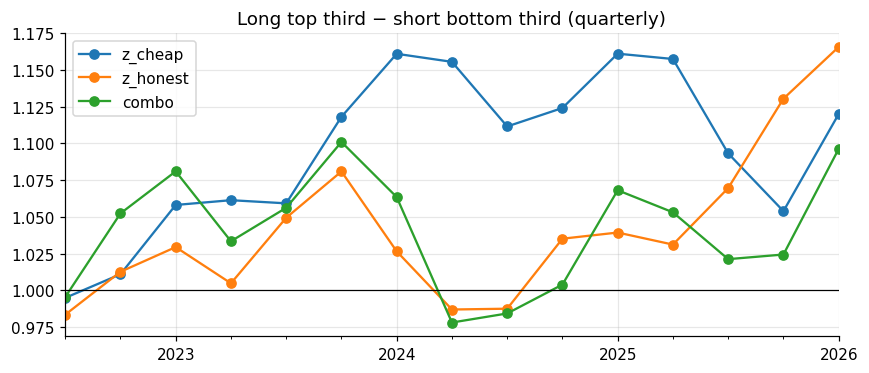

In [14]:
z = lambda s: (s - s.mean()) / s.std(ddof=0)
X["z_cheap"] = X.groupby("q").disc.transform(lambda s: z(-s))
X["z_honest"] = X.groupby("q").optimism.transform(lambda s: z(-s))
X["combo"] = X.z_cheap + X.z_honest
res = {}
for sig in ["z_cheap", "z_honest", "combo"]:
    r = []
    for q, g in X.dropna(subset=["fret1", sig]).groupby("q"):
        if len(g) < 9: continue
        k = len(g) // 3
        g = g.sort_values(sig)
        r.append((q, g.tail(k).fret1.mean() - g.head(k).fret1.mean()))
    res[sig] = pd.Series(dict(r))
R = pd.DataFrame(res)
summ = pd.DataFrame({"quarters": R.count(), "mean per q": R.mean(), "hit rate": (R > 0).mean(),
                     "ann. Sharpe": R.mean() / R.std() * 2, "t": R.mean() / (R.std() / np.sqrt(R.count()))})
print(summ.round(3).to_string())
(1 + R.fillna(0)).cumprod().plot(figsize=(8, 3.5), marker="o", title="Long top third − short bottom third (quarterly)")
plt.axhline(1, c="k", lw=0.8); plt.tight_layout(); plt.show()

## 9. Takeaways
Filled in after running; see the summary printed in the next cell and the discussion in the chat.